# Real-time image enhancement: how fast can a small U-Net run, and what does speed cost in quality?

**Author:** Jahid Hasan Jony · short self-directed engineering study

Video enhancement (for example of endoscopy streams) has a hard latency budget: at 30 fps, each frame gets **33.3 ms** for everything, from camera frame to enhanced output. This notebook:

1. Trains small residual **U-Nets** of three widths to enhance dark, noisy frames (low-light + sensor noise).
2. Measures **per-frame latency at 640×480, batch size 1** across backends: PyTorch CPU, PyTorch GPU (Apple MPS or CUDA) in FP32 and FP16, and **ONNX Runtime**.
3. Checks that exported and half-precision models still give the same answers (max output difference, PSNR).
4. Profiles the **end-to-end pipeline** (camera frame → preprocessing → inference → postprocessing) to see where time actually goes.

Training images are scikit-learn's bundled sample photos (no download). The point is the deployment trade-offs, not state-of-the-art enhancement quality.

## 1. Setup

In [13]:
import os, time, json, platform, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_sample_images

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    GPU = "cuda"
elif torch.backends.mps.is_available():
    GPU = "mps"
else:
    GPU = None
print("PyTorch", torch.__version__, "| GPU backend:", GPU, "| machine:", platform.platform())

CFG = dict(
    WIDTHS=[8, 16, 32],     # base channels of the U-Net (bigger = slower, usually better)
    H=480, W=640,           # frame size for latency tests
    TRAIN_STEPS=1500,
    BATCH=16, PATCH=128, LR=2e-3,
    WARMUP=10, ITERS=100, ITERS_CPU=30,
    QUICK=False,
)
if CFG["QUICK"]:
    CFG.update(TRAIN_STEPS=100, ITERS=20, ITERS_CPU=5, WARMUP=3)
BUDGET_MS = 1000 / 30
os.makedirs("results", exist_ok=True)
CFG

PyTorch 2.15.0 | GPU backend: mps | machine: macOS-27.2.1-arm64-arm-64bit


{'WIDTHS': [8, 16, 32],
 'H': 480,
 'W': 640,
 'TRAIN_STEPS': 1500,
 'BATCH': 16,
 'PATCH': 128,
 'LR': 0.002,
 'WARMUP': 10,
 'ITERS': 100,
 'ITERS_CPU': 30,
 'QUICK': False}

## 2. Data: clean images and a degradation model

Degradation = darker exposure (gain 0.3–0.7) + Gaussian sensor noise (σ 0.02–0.08). The model learns to map degraded → clean. The left 70% of each image is used for training, the right 30% for testing.

test crops: (40, 3, 128, 128) | PSNR of degraded input: 13.72 dB


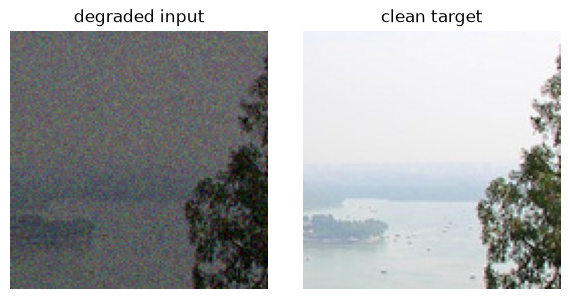

In [14]:
imgs = [im.astype(np.float32) / 255.0 for im in load_sample_images().images]   # 2 photos, 427x640
train_imgs = [torch.tensor(im[:, : int(im.shape[1] * 0.7)]).permute(2, 0, 1) for im in imgs]
test_imgs = [torch.tensor(im[:, int(im.shape[1] * 0.7):]).permute(2, 0, 1) for im in imgs]

def degrade(x, g=None):
    # x: (B,3,H,W) in [0,1]
    g = g or torch.Generator(device="cpu").manual_seed(random.randint(0, 1 << 30))
    B = x.shape[0]
    gain = 0.3 + 0.4 * torch.rand(B, 1, 1, 1, generator=g)
    sigma = 0.02 + 0.06 * torch.rand(B, 1, 1, 1, generator=g)
    return (x * gain + sigma * torch.randn(x.shape, generator=g)).clamp(0, 1)

def random_crops(sources, n, p, g=None):
    out = []
    for _ in range(n):
        im = sources[random.randrange(len(sources))]
        y = random.randint(0, im.shape[1] - p); x = random.randint(0, im.shape[2] - p)
        out.append(im[:, y:y + p, x:x + p])
    return torch.stack(out)

g_test = torch.Generator().manual_seed(123)
random.seed(123)
test_clean = random_crops(test_imgs, 40, 128)
test_noisy = degrade(test_clean, g_test)
random.seed(SEED)

def psnr(a, b):
    mse = ((a.float() - b.float()) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)
    return (10 * torch.log10(1 / mse)).mean().item()

print("test crops:", tuple(test_clean.shape), "| PSNR of degraded input:", round(psnr(test_noisy, test_clean), 2), "dB")
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(test_noisy[0].permute(1, 2, 0)); ax[0].set_title("degraded input"); ax[0].axis("off")
ax[1].imshow(test_clean[0].permute(1, 2, 0)); ax[1].set_title("clean target"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 3. Model: a small residual U-Net with adjustable width

In [15]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, w=16):
        super().__init__()
        self.e1, self.e2, self.e3 = block(3, w), block(w, 2 * w), block(2 * w, 4 * w)
        self.u2 = nn.ConvTranspose2d(4 * w, 2 * w, 2, stride=2)
        self.d2 = block(4 * w, 2 * w)
        self.u1 = nn.ConvTranspose2d(2 * w, w, 2, stride=2)
        self.d1 = block(2 * w, w)
        self.out = nn.Conv2d(w, 3, 1)
    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(F.max_pool2d(e1, 2))
        e3 = self.e3(F.max_pool2d(e2, 2))
        d2 = self.d2(torch.cat([self.u2(e3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return x + self.out(d1)          # residual: predict the correction

def n_params(m): return sum(p.numel() for p in m.parameters())
for w in CFG["WIDTHS"]:
    print(f"width {w:>2}: {n_params(UNet(w))/1e3:.0f}k parameters")

width  8: 29k parameters
width 16: 117k parameters
width 32: 467k parameters


## 4. Train one model per width

In [16]:
train_dev = GPU or "cpu"
models = {}
for w in CFG["WIDTHS"]:
    torch.manual_seed(SEED); random.seed(SEED)
    m = UNet(w).to(train_dev)
    opt = torch.optim.Adam(m.parameters(), lr=CFG["LR"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["TRAIN_STEPS"])
    t0 = time.time()
    for step in range(CFG["TRAIN_STEPS"]):
        clean = random_crops(train_imgs, CFG["BATCH"], CFG["PATCH"])
        if random.random() < 0.5: clean = clean.flip(-1)
        noisy = degrade(clean)
        loss = F.l1_loss(m(noisy.to(train_dev)), clean.to(train_dev))
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step == 0 or (step + 1) % 500 == 0:
            print(f"  width {w} step {step+1}/{CFG['TRAIN_STEPS']}  L1 {loss.item():.4f}")
    models[w] = m.eval().cpu()
    print(f"width {w}: trained in {time.time()-t0:.0f}s | test PSNR {psnr(models[w](test_noisy).clamp(0,1).detach(), test_clean):.2f} dB")

  width 8 step 1/1500  L1 0.2112
  width 8 step 500/1500  L1 0.0724
  width 8 step 1000/1500  L1 0.0683
  width 8 step 1500/1500  L1 0.0540
width 8: trained in 81s | test PSNR 22.33 dB
  width 16 step 1/1500  L1 0.3209
  width 16 step 500/1500  L1 0.0673
  width 16 step 1000/1500  L1 0.0628
  width 16 step 1500/1500  L1 0.0508
width 16: trained in 141s | test PSNR 22.84 dB
  width 32 step 1/1500  L1 0.2817
  width 32 step 500/1500  L1 0.0645
  width 32 step 1000/1500  L1 0.0660
  width 32 step 1500/1500  L1 0.0509
width 32: trained in 215s | test PSNR 22.53 dB


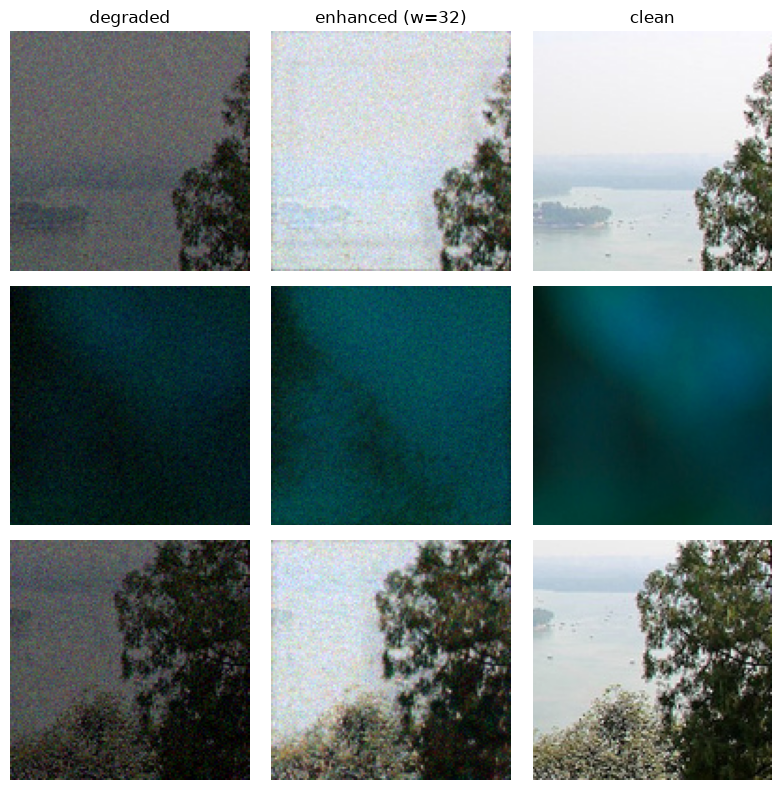

In [17]:
w_show = CFG["WIDTHS"][-1]
with torch.no_grad():
    out = models[w_show](test_noisy[:3]).clamp(0, 1)
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j, (img, t) in enumerate([(test_noisy[i], "degraded"), (out[i], f"enhanced (w={w_show})"), (test_clean[i], "clean")]):
        axes[i, j].imshow(img.permute(1, 2, 0)); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(t)
plt.tight_layout(); plt.savefig("results/examples.png", dpi=150); plt.show()

## 5. Latency at 640×480, batch size 1

Each configuration is warmed up first, then timed frame by frame. GPU timings synchronize the device before stopping the clock, otherwise GPU work is queued and the numbers look unrealistically fast.

In [18]:
def sync(dev):
    if dev == "cuda": torch.cuda.synchronize()
    elif dev == "mps": torch.mps.synchronize()

def bench(fn, dev, iters):
    for _ in range(CFG["WARMUP"]): fn()
    sync(dev); times = []
    for _ in range(iters):
        t0 = time.perf_counter(); fn(); sync(dev)
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times)), float(np.percentile(times, 95))

frame = torch.rand(1, 3, CFG["H"], CFG["W"])
rows, outputs = [], {}

for w, m in models.items():
    ref = None
    # PyTorch CPU, FP32
    mc = m.cpu().eval()
    with torch.inference_mode():
        ref = mc(frame)
        med, p95 = bench(lambda: mc(frame), "cpu", CFG["ITERS_CPU"])
    rows.append(dict(width=w, backend="PyTorch CPU FP32", median_ms=med, p95_ms=p95, max_abs_diff=0.0))
    # PyTorch GPU, FP32 and FP16
    if GPU:
        for prec in ["FP32", "FP16"]:
            try:
                mg = UNet(w); mg.load_state_dict(m.state_dict()); mg = mg.to(GPU).eval()
                xg = frame.to(GPU)
                if prec == "FP16": mg, xg = mg.half(), xg.half()
                with torch.inference_mode():
                    diff = (mg(xg).float().cpu() - ref).abs().max().item()
                    med, p95 = bench(lambda: mg(xg), GPU, CFG["ITERS"])
                rows.append(dict(width=w, backend=f"PyTorch {GPU.upper()} {prec}", median_ms=med, p95_ms=p95, max_abs_diff=diff))
            except Exception as e:
                print(f"  width {w} {GPU} {prec} skipped: {type(e).__name__}: {e}")
    print(f"width {w}: PyTorch done")

pd.DataFrame(rows).round(3)

width 8: PyTorch done
width 16: PyTorch done
width 32: PyTorch done


,width,backend,median_ms,p95_ms,max_abs_diff
0,8,PyTorch CPU FP32,75.084,79.745,0.000
1,8,PyTorch MPS FP32,7.548,8.822,0.000
2,8,PyTorch MPS FP16,5.421,6.345,0.001
3,16,PyTorch CPU FP32,151.536,152.905,0.000
4,16,PyTorch MPS FP32,15.384,16.085,0.000
5,16,PyTorch MPS FP16,11.823,12.570,0.001
6,32,PyTorch CPU FP32,306.435,310.861,0.000
7,32,PyTorch MPS FP32,38.219,39.024,0.000
8,32,PyTorch MPS FP16,31.267,31.837,0.001


## 6. Export to ONNX and run with ONNX Runtime

The exported model must give the same output as PyTorch; the maximum absolute difference is reported for every backend.

In [19]:
import onnx, onnxruntime as ort
print("ONNX Runtime", ort.__version__, "| available providers:", ort.get_available_providers())

def export_onnx(m, path):
    m = m.cpu().eval()
    try:
        torch.onnx.export(m, frame, path, input_names=["input"], output_names=["output"], opset_version=17, dynamo=False)
    except TypeError:   # older PyTorch without the dynamo argument
        torch.onnx.export(m, frame, path, input_names=["input"], output_names=["output"], opset_version=17)
    onnx.checker.check_model(onnx.load(path))

providers = [p for p in ["CoreMLExecutionProvider", "CUDAExecutionProvider", "CPUExecutionProvider"] if p in ort.get_available_providers()]
for w, m in models.items():
    path = f"results/unet_w{w}.onnx"
    export_onnx(m, path)
    with torch.inference_mode():
        ref = m.cpu()(frame).numpy()
    x = frame.numpy()
    for prov in providers:
        try:
            sess = ort.InferenceSession(path, providers=[prov])
            name = sess.get_inputs()[0].name
            out = sess.run(None, {name: x})[0]
            diff = float(np.abs(out - ref).max())
            med, p95 = bench(lambda: sess.run(None, {name: x}), "cpu", CFG["ITERS_CPU"] if prov == "CPUExecutionProvider" else CFG["ITERS"])
            label = "ONNX Runtime " + prov.replace("ExecutionProvider", "")
            rows.append(dict(width=w, backend=label, median_ms=med, p95_ms=p95, max_abs_diff=diff))
        except Exception as e:
            print(f"  width {w} {prov} skipped: {type(e).__name__}: {str(e)[:120]}")
    print(f"width {w}: ONNX done ({os.path.getsize(path)/1e6:.2f} MB)")

L = pd.DataFrame(rows)
L["fps"] = 1000 / L.median_ms
L["meets_30fps"] = L.p95_ms <= BUDGET_MS
L.to_csv("results/latency.csv", index=False)
L.round(3)

ONNX Runtime 1.32.0 | available providers: ['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']


/var/folders/1d/6j7tzbxx3j977hdjqv28d4jm0000gn/T/ipykernel_79633/1450497197.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, frame, path, input_names=["input"], output_names=["output"], opset_version=17, dynamo=False)
2026-11-26 13:04:53.940 python[79633:3810631] 2026-11-26 13:04:53.941854 [W:onnxruntime:, coreml_execution_provider.cc:141 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 3 number of nodes in the graph: 28 number of nodes supported by CoreML: 26
2026-11-26 13:04:54.275 python[79633:3810631] 2026-11-26 13:04:54.276531 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeI

width 8: ONNX done (0.12 MB)


2026-11-26 13:04:57.301 python[79633:3810631] 2026-11-26 13:04:57.302322 [W:onnxruntime:, coreml_execution_provider.cc:141 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 3 number of nodes in the graph: 28 number of nodes supported by CoreML: 26
2026-11-26 13:04:57.521 python[79633:3810631] 2026-11-26 13:04:57.522855 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-26 13:04:57.521 python[79633:3810631] 2026-11-26 13:04:57.522886 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.


width 16: ONNX done (0.47 MB)


2026-11-26 13:05:04.112 python[79633:3810631] 2026-11-26 13:05:04.113210 [W:onnxruntime:, coreml_execution_provider.cc:141 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 3 number of nodes in the graph: 28 number of nodes supported by CoreML: 26
2026-11-26 13:05:04.323 python[79633:3810631] 2026-11-26 13:05:04.324483 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-26 13:05:04.323 python[79633:3810631] 2026-11-26 13:05:04.324512 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.


width 32: ONNX done (1.87 MB)


,width,backend,median_ms,p95_ms,max_abs_diff,fps,meets_30fps
0,8,PyTorch CPU FP32,75.084,79.745,0.000,13.318,False
1,8,PyTorch MPS FP32,7.548,8.822,0.000,132.479,True
2,8,PyTorch MPS FP16,5.421,6.345,0.001,184.464,True
3,16,PyTorch CPU FP32,151.536,152.905,0.000,6.599,False
4,16,PyTorch MPS FP32,15.384,16.085,0.000,65.001,True
5,16,PyTorch MPS FP16,11.823,12.570,0.001,84.579,True
6,32,PyTorch CPU FP32,306.435,310.861,0.000,3.263,False
7,32,PyTorch MPS FP32,38.219,39.024,0.000,26.165,False
8,32,PyTorch MPS FP16,31.267,31.837,0.001,31.983,True
9,8,ONNX Runtime CoreML,12.200,14.008,0.001,81.966,True


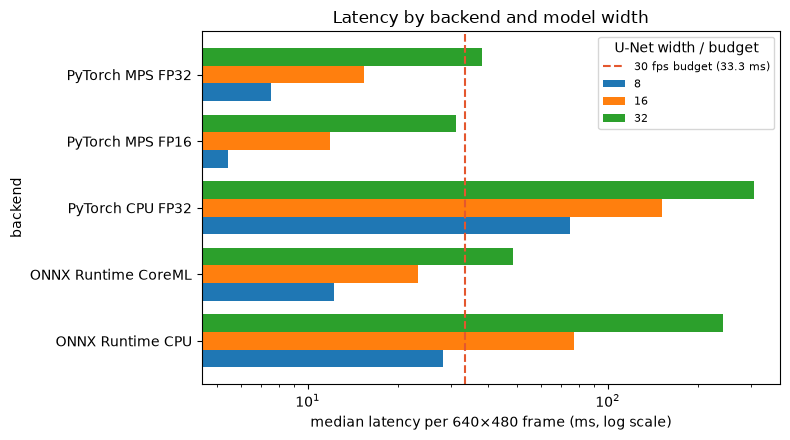

In [20]:
piv = L.pivot(index="backend", columns="width", values="median_ms")
ax = piv.plot.barh(figsize=(8, 0.6 * len(piv) + 1.5), width=0.8)
ax.axvline(BUDGET_MS, color="#E4572E", ls="--", lw=1.5, label="30 fps budget (33.3 ms)")
ax.set_xlabel("median latency per 640×480 frame (ms, log scale)"); ax.set_xscale("log")
ax.legend(title="U-Net width / budget", fontsize=8); ax.set_title("Latency by backend and model width")
plt.tight_layout(); plt.savefig("results/latency.png", dpi=150); plt.show()

## 7. Does speed cost quality?

FP16 and ONNX should not change quality; width does. PSNR on the 40 held-out test crops.

 width  params_k  psnr_fp32  psnr_fp16  psnr_input
     8     29.48      22.33      22.32       13.72
    16    117.08      22.84      22.84       13.72
    32    466.60      22.53      22.53       13.72


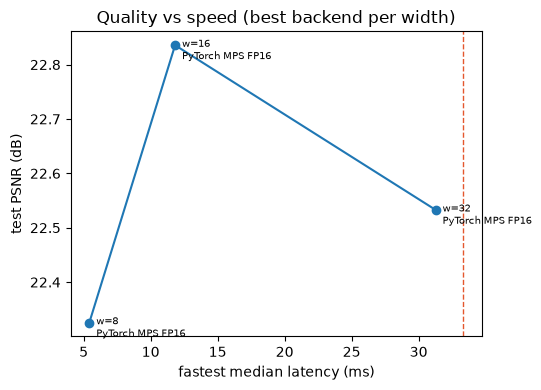

In [21]:
qual = []
for w, m in models.items():
    with torch.inference_mode():
        p32 = psnr(m.cpu()(test_noisy).clamp(0, 1), test_clean)
        row = dict(width=w, params_k=n_params(m) / 1e3, psnr_fp32=p32)
        if GPU:
            try:
                mh = UNet(w); mh.load_state_dict(m.state_dict()); mh = mh.to(GPU).half().eval()
                row["psnr_fp16"] = psnr(mh(test_noisy.to(GPU).half()).float().clamp(0, 1).cpu(), test_clean)
            except Exception as e:
                print("fp16 quality skipped:", e)
    qual.append(row)
Q = pd.DataFrame(qual)
Q["psnr_input"] = psnr(test_noisy, test_clean)
print(Q.round(2).to_string(index=False))

best = L.loc[L.groupby("width").median_ms.idxmin()][["width", "backend", "median_ms"]]
QB = Q.merge(best, on="width")
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(QB.median_ms, QB.psnr_fp32, "o-")
for _, r in QB.iterrows():
    ax.annotate(f"w={int(r.width)}\n{r.backend}", (r.median_ms, r.psnr_fp32), fontsize=7, xytext=(5, -10), textcoords="offset points")
ax.axvline(BUDGET_MS, color="#E4572E", ls="--", lw=1)
ax.set_xlabel("fastest median latency (ms)"); ax.set_ylabel("test PSNR (dB)")
ax.set_title("Quality vs speed (best backend per width)")
plt.tight_layout(); plt.savefig("results/quality_vs_speed.png", dpi=150); plt.show()

## 8. End-to-end pipeline: where does the time go?

A camera delivers uint8 frames (H×W×3). The full path is: convert to tensor and normalize → move to device → model → move back → convert to uint8. Timed per stage on the fastest PyTorch GPU configuration (or CPU if no GPU).

Pipeline on mps FP16, width 16: total 21.1 ms/frame (~47 fps)
preprocess                2.4 %
to device                 7.0 %
inference                85.4 %
to host + postprocess     5.2 %
dtype: str


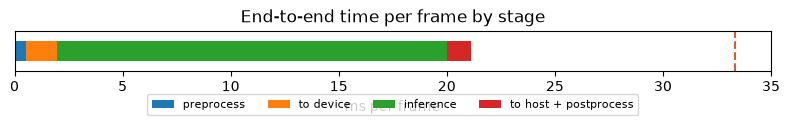

In [22]:
dev = GPU or "cpu"
w_pipe = CFG["WIDTHS"][1]
mp = UNet(w_pipe); mp.load_state_dict(models[w_pipe].state_dict()); mp = mp.to(dev).eval()
half = dev != "cpu" and any((L.width == w_pipe) & (L.backend == f"PyTorch {dev.upper()} FP16"))
if half: mp = mp.half()
cam = (np.random.rand(CFG["H"], CFG["W"], 3) * 255).astype(np.uint8)

stages = {"preprocess": [], "to device": [], "inference": [], "to host + postprocess": []}
with torch.inference_mode():
    for i in range(CFG["WARMUP"] + CFG["ITERS"]):
        t0 = time.perf_counter()
        x = torch.from_numpy(cam).permute(2, 0, 1).unsqueeze(0).float().div_(255)
        t1 = time.perf_counter()
        x = x.to(dev); x = x.half() if half else x; sync(dev)
        t2 = time.perf_counter()
        y = mp(x); sync(dev)
        t3 = time.perf_counter()
        out = (y.float().clamp_(0, 1).mul_(255).byte().squeeze(0).permute(1, 2, 0).cpu().numpy())
        t4 = time.perf_counter()
        if i >= CFG["WARMUP"]:
            for k, (a, b) in zip(stages, [(t0, t1), (t1, t2), (t2, t3), (t3, t4)]):
                stages[k].append((b - a) * 1000)

S = pd.Series({k: float(np.median(v)) for k, v in stages.items()})
total = S.sum()
print(f"Pipeline on {dev}{' FP16' if half else ''}, width {w_pipe}: total {total:.1f} ms/frame (~{1000/total:.0f} fps)")
print((S / total * 100).round(1).astype(str) + " %")
ax = S.to_frame("ms").T.plot.barh(stacked=True, figsize=(8, 1.8))
ax.axvline(BUDGET_MS, color="#E4572E", ls="--", lw=1.5)
ax.set_xlabel("ms per frame"); ax.set_yticks([]); ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.45))
ax.set_title("End-to-end time per frame by stage")
plt.tight_layout(); plt.savefig("results/pipeline.png", dpi=150); plt.show()

## 9. Save results

In [23]:
summary = dict(
    config=CFG, machine=platform.platform(), torch=torch.__version__, onnxruntime=ort.__version__, gpu=GPU,
    latency=L.round(4).to_dict(orient="records"),
    quality=Q.round(3).to_dict(orient="records"),
    pipeline=dict(device=dev, fp16=bool(half), width=w_pipe, stages_ms=S.round(3).to_dict(), total_ms=round(float(total), 3)),
)
json.dump(summary, open("results/summary.json", "w"), indent=2)
print(L.sort_values(["width", "median_ms"]).round(2).to_string(index=False))

 width             backend  median_ms  p95_ms  max_abs_diff    fps  meets_30fps
     8    PyTorch MPS FP16       5.42    6.34           0.0 184.46         True
     8    PyTorch MPS FP32       7.55    8.82           0.0 132.48         True
     8 ONNX Runtime CoreML      12.20   14.01           0.0  81.97         True
     8    ONNX Runtime CPU      28.30   29.30           0.0  35.33         True
     8    PyTorch CPU FP32      75.08   79.75           0.0  13.32        False
    16    PyTorch MPS FP16      11.82   12.57           0.0  84.58         True
    16    PyTorch MPS FP32      15.38   16.09           0.0  65.00         True
    16 ONNX Runtime CoreML      23.31   24.52           0.0  42.89         True
    16    ONNX Runtime CPU      77.23   78.14           0.0  12.95        False
    16    PyTorch CPU FP32     151.54  152.91           0.0   6.60        False
    32    PyTorch MPS FP16      31.27   31.84           0.0  31.98         True
    32    PyTorch MPS FP32      38.22   

## Notes and limitations
- Latency depends heavily on hardware; all numbers are from one machine (printed in section 1) and batch size 1.
- Training data is two bundled photos with synthetic degradation, so quality numbers are illustrative only.
- Next steps: TensorRT on an NVIDIA GPU, INT8 quantization, channels-last memory format, and overlapping capture with inference (pipelining) to hide transfer time.